In [1]:
# Reference: https://herbie.readthedocs.io/en/stable/gallery/bonus_notebooks/time-height.html
from functions import *
from herbie import Herbie, FastHerbie, HerbieLatest
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
import numpy as np
from datetime import datetime, timedelta


# Define the points of interest
cityName = "Louisville, KY (KSDF)"
points = pd.DataFrame({"longitude": [-85.735122], # 
                       "latitude":  [38.171471],  # Louisville, KY (KSDF)
                       })



In [ ]:
H = Herbie("2021-07-11", model="gfs_wave")
H.PRODUCTS

✅ Found ┊ model=gfs_wave ┊ product=arctic.9km ┊ 2021-Jul-11 00:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ aws


{'arctic.9km': 'Arctic; 9-km resolution',
 'atlocn.0p16': 'North Atlantic 0.16 deg resolution',
 'epacif.0p16': 'Eastern Pacific; .16 deg resolution',
 'global.0p16': 'Global; 0.16 deg resolution',
 'global.0p25': 'Global; 0.25 deg resolution',
 'gsouth.0p25': 'Global South; 0.25 deg resolution',
 'wcoast.0p16': 'West Coast; 0.16 deg resolution'}

In [26]:
H = Herbie("2021-07-11", model="gfs_wave", product='global.0p16')
H.inventory()

✅ Found ┊ model=gfs_wave ┊ product=global.0p16 ┊ 2021-Jul-11 00:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ aws


,grib_message,start_byte,end_byte,range,reference_time,valid_time,variable,level,forecast_time,search_this
0,1,0,638862.0,0-638862,2021-07-11,2021-07-11,WIND,surface,anl,:WIND:surface:anl
1,2,638863,1546627.0,638863-1546627,2021-07-11,2021-07-11,WDIR,surface,anl,:WDIR:surface:anl
2,3,1546628,2193650.0,1546628-2193650,2021-07-11,2021-07-11,UGRD,surface,anl,:UGRD:surface:anl
3,4,2193651,2828456.0,2193651-2828456,2021-07-11,2021-07-11,VGRD,surface,anl,:VGRD:surface:anl
4,5,2828457,3204760.0,2828457-3204760,2021-07-11,2021-07-11,HTSGW,surface,anl,:HTSGW:surface:anl
5,6,3204761,3644335.0,3204761-3644335,2021-07-11,2021-07-11,PERPW,surface,anl,:PERPW:surface:anl
6,7,3644336,4463778.0,3644336-4463778,2021-07-11,2021-07-11,DIRPW,surface,anl,:DIRPW:surface:anl
7,8,4463779,4795023.0,4463779-4795023,2021-07-11,2021-07-11,WVHGT,surface,anl,:WVHGT:surface:anl
8,9,4795024,5224217.0,4795024-5224217,2021-07-11,2021-07-11,SWELL,1 in sequence,anl,:SWELL:1 in sequence:anl
9,10,5224218,5602375.0,5224218-5602375,2021-07-11,2021-07-11,SWELL,2 in sequence,anl,:SWELL:2 in sequence:anl


In [27]:
H.xarray("SWELL:1 in sequence", remove_grib=False, backend_kwargs={'decode_times':False})

<xarray.Dataset> Size: 4MB
Dimensions:              (latitude: 406, longitude: 2160)
Coordinates:
    time                 int64 8B 1625961600
    step                 float64 8B 0.0
    orderedSequenceData  float64 8B 1.0
  * latitude             (latitude) float64 3kB 52.5 52.33 ... -14.83 -15.0
  * longitude            (longitude) float64 17kB 0.0 0.1667 ... 359.7 359.8
    valid_time           float64 8B ...
    gribfile_projection  object 8B None
Data variables:
    shts                 (latitude, longitude) float32 4MB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    model:                   gfs_wave
    product:                 global.0p16
    description:             NOAA Global Forecast System (GFS) - Wave Products
    remote_grib:             https://noaa-gfs-bdp-pds.s3.amazonaws.com/gfs.20...
    local_grib:              /Users/jglarson/data/gfs_wave/20210711/subset_b4...
    search:                  SWELL:1 in sequence

In [ ]:
H.xarray("SWELL:1 in sequence", remove_grib=False, backend_kwargs={'decode_times':False}
              )['shts'].values.max()

# why are the max and min values both nan?

np.float32(nan)

# Old WxChallenge Code below for reference

# Generate a table of data

In [8]:
forecastInit = get_latest_forecast_cycle(model='HRRR')
# forecastInit = pd.Timestamp(2025, 3, 5, 18, 0)

# Use the function to calculate forecast range
forecastRange = calculate_forecast_range(forecastInit)

H = FastHerbie(
    [forecastInit],
    model="hrrr",
    product="sfc",
    fxx=forecastRange,
)

# 2m temperature
t2m_HRRR = H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
                  ).herbie.pick_points(points, method="nearest"
                                       )['t2m'].sel(point=0)[1:]

t2m_HRRR = (t2m_HRRR - 273.15) * 1.8 + 32
t2m_max_HRRR = float(t2m_HRRR.max().values)
t2m_min_HRRR = float(t2m_HRRR.min().values)

model_init_HRRR = convert_time_to_datetime64(t2m_HRRR.time.values)
model_valid_times_HRRR = convert_time_to_datetime64(t2m_HRRR.valid_time.values)

# 10m wind speed
si10_HRRR = H.xarray(":WIND", backend_kwargs={'decode_times':False}
                     ).herbie.pick_points(points, method="nearest"
                                          )['si10'].sel(point=0)[1:]
si10_max_HRRR = float(si10_HRRR.max().values)
si10_max_HRRR = si10_max_HRRR * 1.94384  # Convert m/s to knots

# Total precipitation
tp_HRRR = H.xarray("APCP", backend_kwargs={'decode_times':False}
              ).herbie.pick_points(points, method="nearest"
                                   )['tp'].sel(point=0)
tp_HRRR = tp_HRRR * 0.0393701  # Convert mm (1 kg m^-2 = 1 mm) to inches
tp_HRRR = tp_HRRR[1:] - tp_HRRR[0]  # Subtract the total precipitation that falls before 06UTC
tp_max_HRRR = float(tp_HRRR.max().values)


## Make the table

# Create the title
title = f"Forecasting for {cityName} \nValid: {str(model_valid_times_HRRR[0])} - {str(model_valid_times_HRRR[-1])} UTC"
# {tomorrow.strftime('%B %d')} 06UTC - {day_after_tomorrow.strftime('%B %d')} 06UTC"

# Create the table
data = {
    "Model": ["HRRR"],  # "NBM"],
    "High (°F)": [t2m_max_HRRR],  # np.nan],  # Replace np.nan with actual values if available
    "Low (°F)": [t2m_min_HRRR],  # np.nan],   # Replace np.nan with actual values if available
    "Precipitation (in)": [tp_max_HRRR],  # np.nan],  # Replace np.nan with actual values if available
    "Wind Speed (kt)": [si10_max_HRRR],  # np.nan]  # Replace np.nan with actual values if available
    "Model Init": f" {str(model_init_HRRR)} UTC",  # np.nan]  # Replace np.nan with actual values if available
}

df_forecast = pd.DataFrame(data).round(2)

# Print the title and table without row numbers
print(title)
print(df_forecast.to_string(index=False))

Forecasting for Louisville, KY (KSDF) 
Valid: 2025-03-19T06 - 2025-03-20T05 UTC
Model  High (°F)  Low (°F)  Precipitation (in)  Wind Speed (kt)         Model Init
 HRRR      63.72      47.1                0.17            18.03  2025-03-18T18 UTC


# ECMWF

In [9]:
forecastInit = get_latest_forecast_cycle(model='ECMWF')

# Use the function to calculate forecast range
forecastRange = calculate_forecast_range(forecastInit)

H = FastHerbie(
    [forecastInit],
    model="ifs",
    product="oper",
    fxx=forecastRange,
)

# Test if the forecast is available
# H.inventory(":2t:.*fcst:nan")

# 2m temperature
t2m_IFS = H.xarray(":2t:", backend_kwargs={'decode_times':False}
                  ).herbie.pick_points(points, method="nearest"
                                       )['t2m'].sel(point=0)

t2m_IFS = (t2m_IFS - 273.15) * 1.8 + 32
t2m_max_IFS = float(t2m_IFS.max().values)
t2m_min_IFS = float(t2m_IFS.min().values)

model_init_IFS = convert_time_to_datetime64(t2m_IFS.time.values)
model_valid_times_IFS = convert_time_to_datetime64(t2m_IFS.valid_time.values)

# 10m wind speed
u10_IFS = H.xarray(":10u:", backend_kwargs={'decode_times':False}
                     ).herbie.pick_points(points, method="nearest"
                                          )['u10'].sel(point=0)
v10_IFS = H.xarray(":10v:", backend_kwargs={'decode_times':False}
                     ).herbie.pick_points(points, method="nearest"
                                          )['v10'].sel(point=0)
# Calculate max wind speed from u and v components
si10_max_IFS = float((np.sqrt(u10_IFS**2 + v10_IFS**2)).max().values)
si10_max_IFS = si10_max_IFS * 1.94384  # Convert m/s to knots

# Total precipitation
tp_IFS = H.xarray(":tp:", backend_kwargs={'decode_times':False}
                     ).herbie.pick_points(points, method="nearest"
                                          )['tp'].sel(point=0)
tp_sum_IFS = float(tp_IFS.sum().values)


# Make the table


# Create the title
title = f"Forecasting for {cityName} - Model initialized {str(model_init_IFS)} UTC\nValid: {str(model_valid_times_IFS[0])} - {str(model_valid_times_IFS[-1])} UTC"
# {tomorrow.strftime('%B %d')} 06UTC - {day_after_tomorrow.strftime('%B %d')} 06UTC"

# Create the table
data = {
    "Model": ["ECMWF IFS"],
    "High (°F)": [t2m_max_IFS],
    "Low (°F)": [t2m_min_IFS],
    "Precipitation (in)": [tp_sum_IFS],
    "Wind Speed (kt)": [si10_max_IFS],
}

df_forecast = pd.DataFrame(data).round(2)

# Print the title and table without row numbers
print(title)
print(df_forecast.to_string(index=False))



Could not find 17/8 GRIB files.


Forecasting for Louisville, KY (KSDF) - Model initialized 2025-03-18T12 UTC
Valid: 2025-03-19T06 - 2025-03-20T03 UTC
    Model  High (°F)  Low (°F)  Precipitation (in)  Wind Speed (kt)
ECMWF IFS      64.91     54.67                0.01            14.28


In [10]:
# Create the title
title = f"Forecasting for {cityName} \nValid: {str(model_valid_times_HRRR[0])} - {str(model_valid_times_HRRR[-1])} UTC"

# Create the table combining both models
data = {
    "Model": ["HRRR", "ECMWF IFS"],
    "High (°F)": [t2m_max_HRRR, t2m_max_IFS],
    "Low (°F)": [t2m_min_HRRR, t2m_min_IFS],
    "Precipitation (in)": [tp_max_HRRR, tp_sum_IFS],
    "Wind Speed (kt)": [si10_max_HRRR, si10_max_IFS],
    "Model Init": [f" {str(model_init_HRRR)} UTC", f" {str(model_init_IFS)} UTC"]
}

df_forecast = pd.DataFrame(data).round(2)

# Print the title and table without row numbers
print(title)
print(df_forecast.to_string(index=False))


Forecasting for Louisville, KY (KSDF) 
Valid: 2025-03-19T06 - 2025-03-20T05 UTC
    Model  High (°F)  Low (°F)  Precipitation (in)  Wind Speed (kt)         Model Init
     HRRR      63.72     47.10                0.17            18.03  2025-03-18T18 UTC
ECMWF IFS      64.91     54.67                0.01            14.28  2025-03-18T12 UTC


# ECMWF Ensemble Forecast

In [2]:
forecastInit = get_latest_forecast_cycle(model='IFS')

# Use the function to calculate forecast range
forecastRange = calculate_forecast_range(forecastInit, model='IFS')

forecastInit
forecastRange

[18, 21, 24, 27, 30, 33, 36, 39]

In [2]:
H = Herbie("2024-03-27 00:00", model="ifs", product="enfo", fxx=6)
ds = H.xarray(":2t:", backend_kwargs={'decode_times':False})

# forecastInit = get_latest_forecast_cycle(model='ECMWF')

# # Use the function to calculate forecast range
# forecastRange = calculate_forecast_range(forecastInit)



✅ Found ┊ model=ifs ┊ product=enfo ┊ 2024-Mar-27 00:00 UTC F06 ┊ GRIB2 @ aws ┊ IDX @ aws


/Users/jglarson/miniconda3/envs/weather-output/lib/python3.13/site-packages/xarray/backends/plugins.py:75: RuntimeWarning: Engine 'gini' loading failed:
cannot inherit frozen dataclass from a non-frozen one
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


Note: Returning a list of [2] xarray.Datasets because cfgrib opened with multiple hypercubes.


In [3]:
forecastInit = get_latest_forecast_cycle(model='IFS')

# Use the function to calculate forecast range
forecastRange = calculate_forecast_range(forecastInit, model='IFS')

variable = "2t" #tp for precipitation
tp_all = []
valid_times = []
# forecast_hours_qpf = range(3,147,3)
model_search_string = ":"+variable+":sfc:"

for t in forecastRange:
    # H = Herbie(model_run.strftime('%Y-%m-%d %H:00'), model="ecmwf", product="enfo", fxx=t)
    H = Herbie(forecastInit, model="ifs", product="enfo", fxx=t)
    tp = H.xarray(":2t:", backend_kwargs={'decode_times':False})[0]
    #tp = tp.rename({"number":"pertubation"})
    tp_all.append(tp)
    valid_times.append(forecastInit + timedelta(hours=t))

ptotal = xr.concat([tp_all[i] for i in range(0,len(forecastRange))], dim='step')


✅ Found ┊ model=ifs ┊ product=enfo ┊ 2025-Mar-28 12:00 UTC F18 ┊ GRIB2 @ aws ┊ IDX @ aws


/Users/jglarson/miniconda3/envs/weather-output/lib/python3.13/site-packages/xarray/backends/plugins.py:75: RuntimeWarning: Engine 'gini' loading failed:
cannot inherit frozen dataclass from a non-frozen one
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


Note: Returning a list of [2] xarray.Datasets because cfgrib opened with multiple hypercubes.
✅ Found ┊ model=ifs ┊ product=enfo ┊ 2025-Mar-28 12:00 UTC F21 ┊ GRIB2 @ aws ┊ IDX @ aws
Note: Returning a list of [2] xarray.Datasets because cfgrib opened with multiple hypercubes.
✅ Found ┊ model=ifs ┊ product=enfo ┊ 2025-Mar-28 12:00 UTC F24 ┊ GRIB2 @ aws ┊ IDX @ aws


WrongLengthError: Wrong message length

Ensemble Temperature Statistics
Statistic  Max Temp (°F)  Min Temp (°F)
     Mean           63.4           61.1
Lower 25%           62.4           60.0
Upper 75%           64.5           62.0


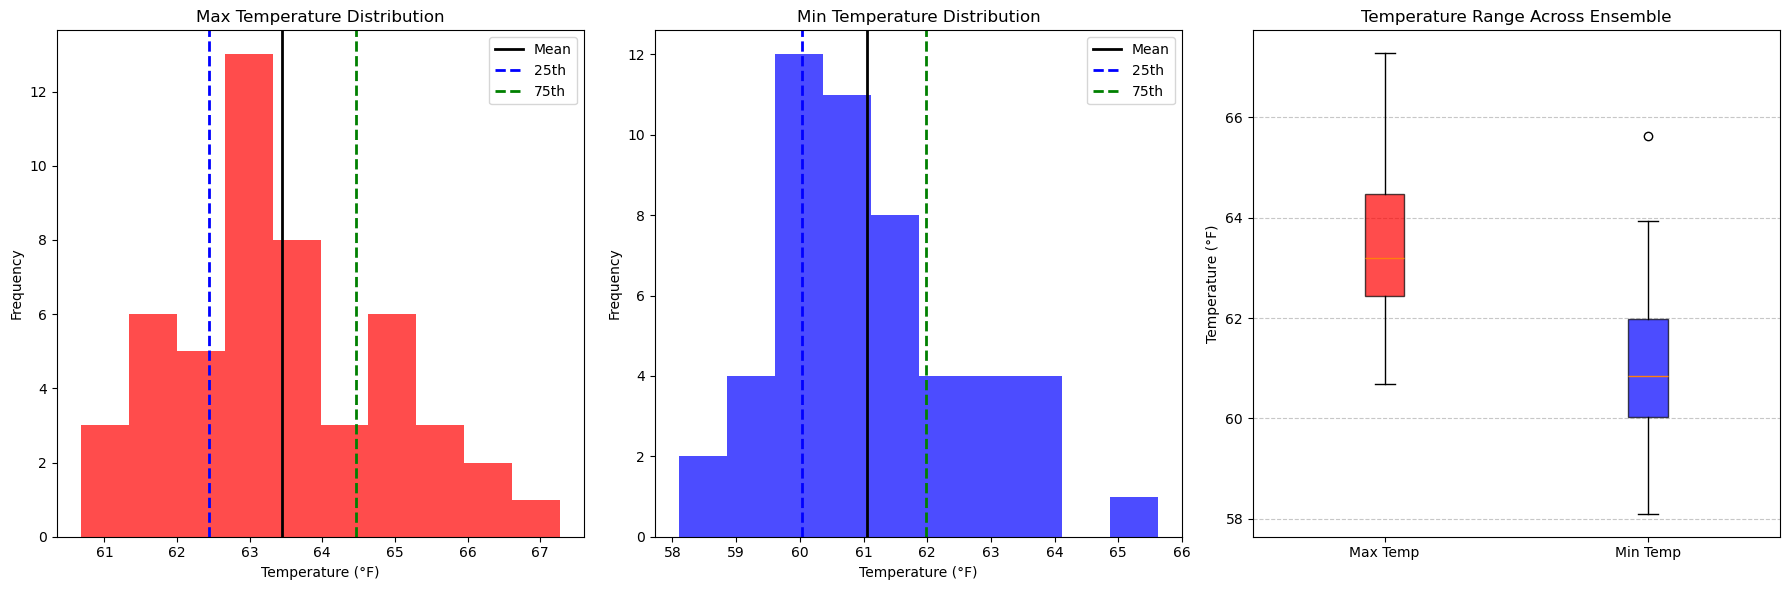


Additional Statistics:
Max Temperature Range: 60.7°F - 67.3°F
Min Temperature Range: 58.1°F - 65.6°F
Ensemble Spread (Max): 1.5°F
Ensemble Spread (Min): 1.5°F


In [9]:
# Get data for all 50 ensemble members
ds = xr.concat([tp_all[i] for i in range(0,len(tp_all))], dim='step').herbie.pick_points(points, method="nearest").sel(point=0)

# Convert temperature from Kelvin to Fahrenheit
ds['t2m_f'] = (ds['t2m'] - 273.15) * 9/5 + 32

# Calculate max and min temperatures for each ensemble member
max_temp = ds['t2m_f'].max(dim='step')
min_temp = ds['t2m_f'].min(dim='step')

# Calculate statistics
max_stats = {
    'Mean': float(max_temp.mean().values),
    '25th': float(max_temp.quantile(0.25).values),
    '75th': float(max_temp.quantile(0.75).values)
}

min_stats = {
    'Mean': float(min_temp.mean().values),
    '25th': float(min_temp.quantile(0.25).values), 
    '75th': float(min_temp.quantile(0.75).values)
}

# Create a summary table
import pandas as pd
stats_df = pd.DataFrame({
    'Statistic': ['Mean', 'Lower 25%', 'Upper 75%'],
    'Max Temp (°F)': [max_stats['Mean'], max_stats['25th'], max_stats['75th']],
    'Min Temp (°F)': [min_stats['Mean'], min_stats['25th'], min_stats['75th']]
})

# Display the table
print("Ensemble Temperature Statistics")
print("==============================")
print(stats_df.to_string(index=False, float_format=lambda x: f"{x:.1f}"))

# Create visualizations
import matplotlib.pyplot as plt
import numpy as np

# Create figure with 3 subplots
fig = plt.figure(figsize=(18, 6))

# 1. Histogram of max temperatures
ax1 = fig.add_subplot(131)
ax1.hist(max_temp.values, bins=10, alpha=0.7, color='red')
ax1.axvline(max_stats['Mean'], color='k', linestyle='-', linewidth=2, label='Mean')
ax1.axvline(max_stats['25th'], color='b', linestyle='--', linewidth=2, label='25th')
ax1.axvline(max_stats['75th'], color='g', linestyle='--', linewidth=2, label='75th')
ax1.set_title('Max Temperature Distribution')
ax1.set_xlabel('Temperature (°F)')
ax1.set_ylabel('Frequency')
ax1.legend()

# 2. Histogram of min temperatures
ax2 = fig.add_subplot(132)
ax2.hist(min_temp.values, bins=10, alpha=0.7, color='blue')
ax2.axvline(min_stats['Mean'], color='k', linestyle='-', linewidth=2, label='Mean')
ax2.axvline(min_stats['25th'], color='b', linestyle='--', linewidth=2, label='25th')
ax2.axvline(min_stats['75th'], color='g', linestyle='--', linewidth=2, label='75th')
ax2.set_title('Min Temperature Distribution')
ax2.set_xlabel('Temperature (°F)')
ax2.set_ylabel('Frequency')
ax2.legend()

# 3. Box and whisker plot
ax3 = fig.add_subplot(133)
box_data = [max_temp.values, min_temp.values]
box = ax3.boxplot(box_data, patch_artist=True)
for patch, color in zip(box['boxes'], ['red', 'blue']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax3.set_xticklabels(['Max Temp', 'Min Temp'])
ax3.set_ylabel('Temperature (°F)')
ax3.set_title('Temperature Range Across Ensemble')
ax3.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# Print some additional statistics
print("\nAdditional Statistics:")
print(f"Max Temperature Range: {max_temp.min().values:.1f}°F - {max_temp.max().values:.1f}°F")
print(f"Min Temperature Range: {min_temp.min().values:.1f}°F - {min_temp.max().values:.1f}°F")
print(f"Ensemble Spread (Max): {max_temp.std().values:.1f}°F")
print(f"Ensemble Spread (Min): {min_temp.std().values:.1f}°F")

# Generate a time series

In [22]:
# https://herbie.readthedocs.io/en/stable/gallery/noaa_models/hrrr.html
H = FastHerbie(
    [get_latest_forecast_cycle()],
    model="hrrr",
    product="sfc",
    fxx=list(range(6, 30)),
)

t2m_ds = H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
                  ).herbie.pick_points(points, method="nearest")

t2m_ds = (t2m_ds['t2m'] - 273.15) * 1.8 + 32

# t2m_ds


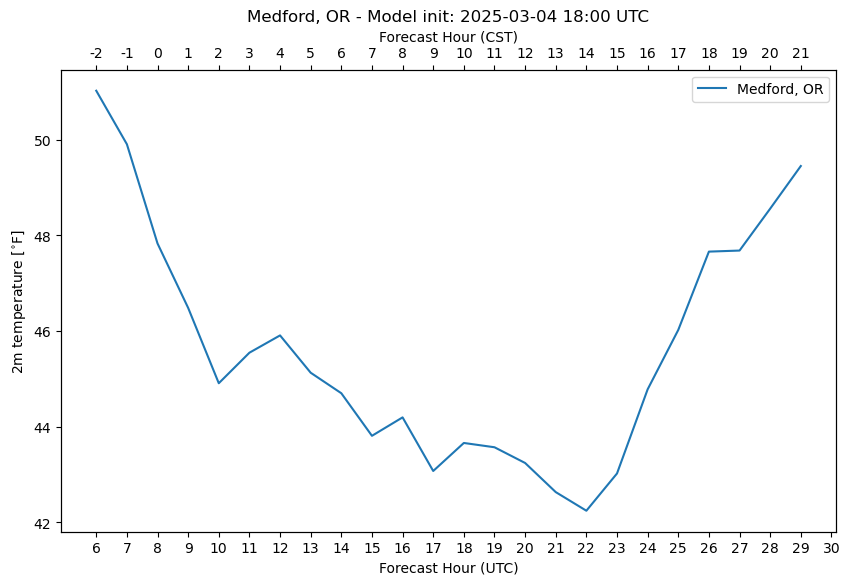

In [ ]:
# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Add title with datetime_index
plt.title(f"{cityName} - Model init: {get_latest_forecast_cycle().strftime('%Y-%m-%d %H:%M')} UTC")

city2 = t2m_ds.sel(point=0).values

# Plot on primary axis (UTC)
ax1.plot(np.arange(6,30), city2, label=cityName)
ax1.set_xlabel('Forecast Hour (UTC)')
ax1.set_ylabel(r'2m temperature [$^{\circ}$F]')
ax1.set_xticks(np.arange(6,31))

# Create secondary x-axis for CST
ax2 = ax1.twiny()
cst_hours = np.arange(0,25)  # UTC-6
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(np.arange(6,30))
ax2.set_xticklabels([str(h-8) for h in range(6,30)])
ax2.set_xlabel('Forecast Hour (CST)')

# Annotate max and min for the city
max_wf = np.max(city2)
min_wf = np.min(city2)
max_wf_idx = np.argmax(city2)
min_wf_idx = np.argmin(city2)

plt.annotate(f'Max: {max_wf:.2f}', xy=(max_wf_idx + 6, max_wf), xytext=(max_wf_idx + 6, max_wf - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_wf:.2f}', xy=(min_wf_idx + 6, min_wf), xytext=(min_wf_idx + 6, min_wf + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))


# Add legend
ax1.legend()

plt.show()

## Precip

### To DO: Modify the tickmarks such that they update based on when the model was intialized

In [20]:
# Load in the data
H = FastHerbie(
    [get_latest_forecast_cycle()],
    model="hrrr",
    product="sfc",
    fxx=list(range(5, 30)),
)
                
tp = H.xarray("APCP", backend_kwargs={'decode_times':False}
              ).herbie.pick_points(points, method="nearest"
                                   )['tp']
tp = tp * 0.0393701  # Convert mm (1 kg m^-2 = 1 mm) to inches
tp = tp[1:] - tp[0]  # Subtract the total precipitation that falls before 06UTC
tp


<xarray.DataArray 'tp' (step: 24, point: 1)> Size: 96B
array([[0.00047244],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00594489]], dtype=float32)
Coordinates:
    time                 int64 8B 1741132800
  * step                 (step) float64 192B 6.0 7.0 8.0 9.0 ... 27.0 28.0 29.0
    surface              float64 8B 0.0
    latitude             (point) float64 8B 42.36
    longitude            (point) float64 8B 237.1
    gribfile_projection  object 8B None
    point_grid_distance  (point) float64 8B 1.457
    point_longitude      (point) float64 8B -122.9
    point_latitude       (point) float64 8B 42.37
Dimensions without coordinates: point

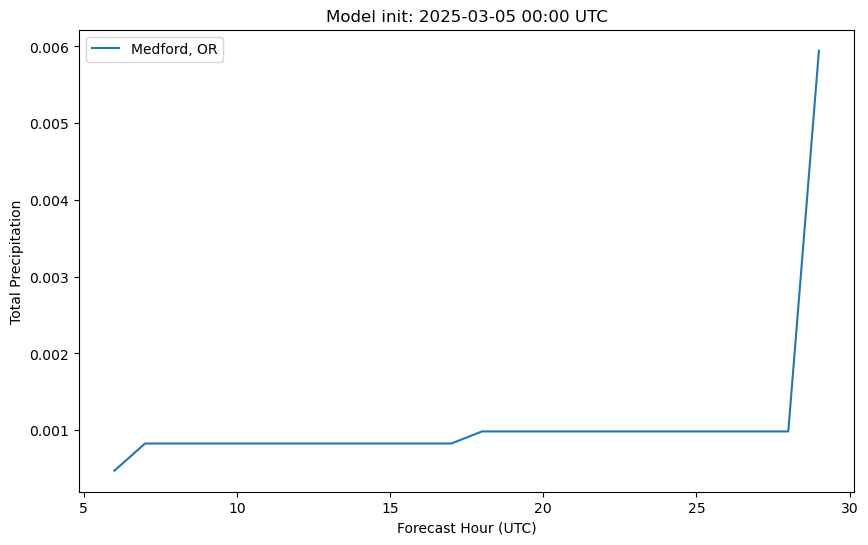

In [22]:

# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Add title with datetime_index
plt.title(f"Model init: {get_latest_forecast_cycle().strftime('%Y-%m-%d %H:%M')} UTC")

city2 = tp.sel(point=0).values

# Plot on primary axis (UTC)
ax1.plot(np.arange(6,30), city2, label='Medford, OR')
ax1.set_xlabel('Forecast Hour (UTC)')
ax1.set_ylabel('Total Precipitation')

# Add legend
ax1.legend()

plt.show()


# TO DO: convert tp from Kg per square meter to inches. Potentially 0.039370079003585

# Add NBM

In [ ]:
# dates = pd.date_range("2024-11-21 18:00", periods=1, freq="1h")
today = pd.Timestamp.now().date()
dates = pd.DatetimeIndex([pd.Timestamp(f"{today} 18:00")])

H = FastHerbie(dates, model="nbm", fxx=list(range(6, 30)), product="co")
H.inventory(":TMP:2 m above ground:.*fcst:nan")

points = pd.DataFrame({"longitude": [-105.082396, -80.172745], # [Fort Collins, Erie]
                       "latitude": [40.548843, 42.083850],
                       })

ds = H.xarray(":TMP:2 m above ground:.*fcst:nan", backend_kwargs={'decode_times':False}
              ).herbie.pick_points(points, method="nearest")

t2m_ds = (ds['t2m'] - 273.15) * 1.8 + 32

👨🏻‍🏭 Created directory: [/Users/jglarson/data/nbm/20241227]


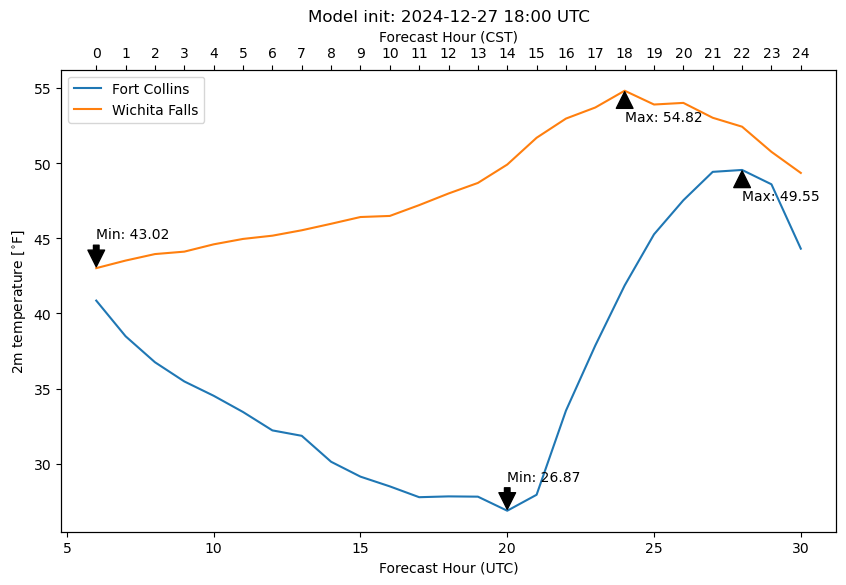

In [ ]:
# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Add title with datetime_index
plt.title(f"Model init: {dates[0].strftime('%Y-%m-%d %H:%M')} UTC")

fort_collins = t2m_ds.sel(point=0).values
city2 = t2m_ds.sel(point=1).values

# Plot on primary axis (UTC)
ax1.plot(np.arange(6,30), fort_collins, label='Fort Collins')
ax1.plot(np.arange(6,30), city2, label='Wichita Falls')
ax1.set_xlabel('Forecast Hour (UTC)')
ax1.set_ylabel(r'2m temperature [$^{\circ}$F]')

# Create secondary x-axis for CST
ax2 = ax1.twiny()
cst_hours = np.arange(0,25)  # UTC-6
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(np.arange(6,30))
ax2.set_xticklabels([str(h-6) for h in range(6,30)])
ax2.set_xlabel('Forecast Hour (CST)')

# Annotate max and min for Fort Collins
max_fc = np.max(fort_collins)
min_fc = np.min(fort_collins)
max_fc_idx = np.argmax(fort_collins)
min_fc_idx = np.argmin(fort_collins)

plt.annotate(f'Max: {max_fc:.2f}', xy=(max_fc_idx + 6, max_fc), xytext=(max_fc_idx + 6, max_fc - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_fc:.2f}', xy=(min_fc_idx + 6, min_fc), xytext=(min_fc_idx + 6, min_fc + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))

# Annotate max and min for Wichita Falls
max_wf = np.max(city2)
min_wf = np.min(city2)
max_wf_idx = np.argmax(city2)
min_wf_idx = np.argmin(city2)

plt.annotate(f'Max: {max_wf:.2f}', xy=(max_wf_idx + 6, max_wf), xytext=(max_wf_idx + 6, max_wf - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_wf:.2f}', xy=(min_wf_idx + 6, min_wf), xytext=(min_wf_idx + 6, min_wf + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))


# Add legend
ax1.legend()

plt.show()